# 12 · From logged episodes to a factored transition model with a guarantee

An MDP is a two-slice network: `(position_t, battery_t, action_t) -> next slice`.

    pos' = clip(pos + act + U, 0, 5),  U in {-1, 0, +1} w.p. (0.1, 0.8, 0.1)   (slip)
    bat' = clip(bat - act + V, 0, 3),  V in { 0, +1}    w.p. (0.7, 0.3)        (recharge)

We flatten episodes into transitions, fit one structural mechanism per
next-state variable, and build per-variable probability sets.  Two details
matter for trajectories:

* visit counts are random and depend on earlier draws, so the sets use
  `sampling="trajectory"` (each interval valid for every sample size);
* the kernel is the product of the per-variable tables, so the global budget
  `delta` is split between the variables (union bound).  Solving over the
  product of the sets (exact vertices / McCormick) happens downstream.

- **NBN API:** `nbn.scm.transitions_from_episodes`, `StructuralCausalModel`,
  `DiscreteAdditiveNoiseMechanism`, `noise_parameter_set`; `nbn.uncertainty.interval_set`.
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn.scm import (
    DiscreteAdditiveNoiseMechanism,
    StructuralCausalModel,
    noise_parameter_set,
    transitions_from_episodes,
)
from nbn.uncertainty import interval_set
from nbn.utils.device import resolve_device
from _figures import BLUE, ORANGE, AQUA, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)



def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The data

200 episodes of 20 steps under a random policy (0 = stay, 1 = move right).

In [2]:
torch.manual_seed(0)
SLIP = torch.tensor([0.1, 0.8, 0.1])
RECHARGE = torch.tensor([0.0, 0.7, 0.3])     # offsets -1, 0, +1


def collect(n_episodes: int = 200, horizon: int = 20) -> dict:
    position = torch.zeros(n_episodes, horizon + 1, dtype=torch.long)
    battery = torch.full((n_episodes, horizon + 1), 3, dtype=torch.long)
    action = torch.randint(0, 2, (n_episodes, horizon))            # 0 = stay, 1 = move right
    for t in range(horizon):
        u = torch.multinomial(SLIP, n_episodes, replacement=True) - 1
        v = torch.multinomial(RECHARGE, n_episodes, replacement=True) - 1
        position[:, t + 1] = (position[:, t] + action[:, t] + u).clamp(0, 5)
        battery[:, t + 1] = (battery[:, t] - action[:, t] + v).clamp(0, 3)
    return transitions_from_episodes({"pos": position.float(), "bat": battery.float()},
                                     {"act": action.float()})


data = collect()
print(f"{int(data['episode'].max()) + 1} episodes -> {data['pos'].numel()} transitions")

200 episodes -> 4000 transitions


## 1. One structural mechanism per next-state variable

In [3]:
model = StructuralCausalModel(
    [("pos", "pos'"), ("act", "pos'"), ("bat", "bat'"), ("act", "bat'")],
    {"pos": ("discrete", 6), "act": ("discrete", 2), "bat": ("discrete", 4),
     "pos'": ("discrete", 6), "bat'": ("discrete", 4)},
    device=device,
)
model.set_mechanism("pos'", DiscreteAdditiveNoiseMechanism(max_offset=1))
model.set_mechanism("bat'", DiscreteAdditiveNoiseMechanism(max_offset=1))
model.auto_mechanisms()
model.fit({k: data[k] for k in ("pos", "act", "bat", "pos'", "bat'")})
for v in ("pos'", "bat'"):
    print(f"{v} noise law: {[round(p, 3) for p in model.mechanisms[v].noise.probs.tolist()]}")

pos' noise law: [0.088, 0.803, 0.11]
bat' noise law: [0.0, 0.688, 0.312]


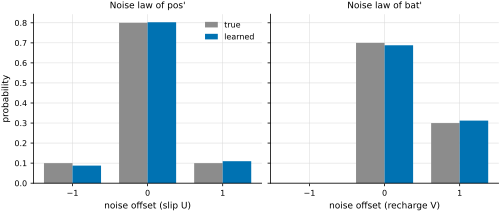

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 3), sharey=True)
for ax, (v, truth, label) in zip(axes, (("pos'", SLIP, "slip U"), ("bat'", RECHARGE, "recharge V"))):
    mech = model.mechanisms[v]
    offsets = to_numpy(mech.noise.offsets)
    ax.bar(offsets - 0.19, to_numpy(truth), 0.38, color=GREY, label="true")
    ax.bar(offsets + 0.19, to_numpy(mech.noise.probs), 0.38, color=BLUE, label="learned")
    ax.set(xticks=offsets, xlabel=f"noise offset ({label})", title=f"Noise law of {v}")
axes[0].set_ylabel("probability")
axes[0].legend(frameon=False)
save(fig, "12_fig1")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

## 2. Probability sets for trajectory data

One set per next-state variable, each at level `1 - delta / 2`, so the kernel's
guarantee is `1 - delta` overall.  Rows never visited get the whole simplex and
are left out of the mean width.

In [5]:
delta, next_state = 0.05, ["pos'", "bat'"]
per_variable = delta / len(next_state)
box = {v: interval_set(model, data, v, delta=per_variable, sampling="trajectory")
       for v in next_state}
pooled = {v: noise_parameter_set(model, data, [v], delta=per_variable,
                                 sampling="trajectory").table_set(v)
          for v in next_state}

print("mean width on seen rows      per-entry box   shared-noise polytope")
for v in next_state:
    seen = ~box[v].unseen
    print(f"  {v:5s}                       {box[v].width()[seen].mean():.3f}"
          f"           {pooled[v].width()[seen].mean():.3f}")

mean width on seen rows      per-entry box   shared-noise polytope
  pos'                        0.157           0.040
  bat'                        0.125           0.046


Width of each row against how often the row was visited.  The per-entry box
shrinks only with the row's own visits; the polytope pools every row through
the shared noise law, so even rarely visited rows get narrow bounds.

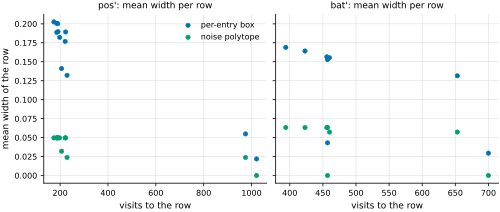

In [6]:
parent_of = {"pos'": ("pos", 6), "bat'": ("bat", 4)}
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 3), sharey=True)
for ax, v in zip(axes, next_state):
    parent, card = parent_of[v]
    rows = data[parent].reshape(-1).long() * 2 + data["act"].reshape(-1).long()   # C order (parent, act)
    visits = torch.bincount(rows, minlength=card * 2)
    seen = to_numpy(~box[v].unseen)
    for name, prob_set, color in (("per-entry box", box, BLUE), ("noise polytope", pooled, AQUA)):
        width = to_numpy(prob_set[v].width().mean(-1))
        ax.scatter(to_numpy(visits)[seen], width[seen], s=20, color=color, label=name)
    ax.set(xlabel="visits to the row", title=f"{v}: mean width per row")
axes[0].set_ylabel("mean width of the row")
axes[0].legend(frameon=False)
save(fig, "12_fig2")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

## 3. Bounds on one transition probability

`P(s' | s, a)` is the product of the per-variable rows; its entry-wise bounds
are products of the factor bounds (all factors are non-negative).

In [7]:
pos, bat, act = 2, 3, 1
row_pos, row_bat = pos * 2 + act, bat * 2 + act      # C order over (parent, act)
print("P(pos'=3, bat'=2 | pos=2, bat=3, act=move)   true value", round(0.8 * 0.7, 3))
for name, sets in (("per-entry box", box), ("noise polytope", pooled)):
    lo_p, hi_p = sets["pos'"].bounds()
    lo_b, hi_b = sets["bat'"].bounds()
    print(f"  {name:15s} [{lo_p[row_pos, 3] * lo_b[row_bat, 2]:.3f}, "
          f"{hi_p[row_pos, 3] * hi_b[row_bat, 2]:.3f}]")

P(pos'=3, bat'=2 | pos=2, bat=3, act=move)   true value 0.56
  per-entry box   [0.345, 0.786]
  noise polytope  [0.449, 0.638]


The same bounds for every next state reachable from `pos=2, bat=3` when moving
right, with the true probabilities.

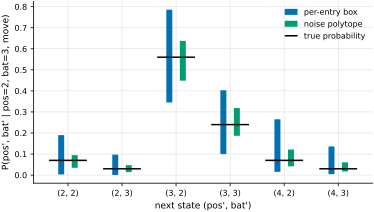

In [8]:
reachable = [(p, b) for p in (2, 3, 4) for b in (2, 3)]
true_pos = {2: 0.1, 3: 0.8, 4: 0.1}
true_bat = {2: 0.7, 3: 0.3}
fig, ax = plt.subplots(figsize=(0.75 * DOUBLE, 3))
for i, (name, sets, color) in enumerate((("per-entry box", box, BLUE), ("noise polytope", pooled, AQUA))):
    lo_p, hi_p = sets["pos'"].bounds()
    lo_b, hi_b = sets["bat'"].bounds()
    lo = [float(lo_p[row_pos, p] * lo_b[row_bat, b]) for p, b in reachable]
    hi = [float(hi_p[row_pos, p] * hi_b[row_bat, b]) for p, b in reachable]
    ax.vlines([j + (i - 0.5) * 0.25 for j in range(len(reachable))], lo, hi, color=color, lw=6,
              label=name)
truth = [true_pos[p] * true_bat[b] for p, b in reachable]
ax.hlines(truth, [j - 0.35 for j in range(len(reachable))], [j + 0.35 for j in range(len(reachable))],
          color=INK, lw=1.5, label="true probability")
ax.set(xticks=range(len(reachable)), xticklabels=[f"({p}, {b})" for p, b in reachable],
       xlabel="next state (pos', bat')", ylabel="P(pos', bat' | pos=2, bat=3, move)")
ax.legend(frameon=False, fontsize=8)
save(fig, "12_fig3")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()